# 기초데이터과학 (01분반)

## 11-1. 상관 분석과 통계적 가설 검정

### Acknowledgement
#### 이 자료는 다음 서적의 내용을 바탕으로 작성되었음
- 쉽게 배우는 파이썬 데이터 분석. 이지스 퍼블리싱
- 혼자 공부하는 데이터 분석 with 파이썬. 한빛미디어
- 누구나 파이썬 통계분석. 한빛아카데미

### 이번 내용에서 다루는 두 가지 질문
- 지난 시간까지는 그래프를 그려 데이터의 관계와 차이를 **눈으로** 확인했음
- 이번에는 데이터 간의 관계를 **숫자로** 판단하는 방법을 다룸

| 질문 | 방법 |
|---|---|
| 두 변수는 얼마나 함께 변하는가? | 상관 분석 |
| 두 집단의 차이는 우연으로 볼 수 있는가? | 통계적 가설 검정 |

---

## Part 1. 상관 분석 (Correlation analysis)

- 두 변수가 서로 관련이 있는지 상관관계를 분석하는 통계적 방법
- 관계의 방향과 관계의 강도를 분석할 수 있음
  - 관계의 방향: 한 변수가 증가할 때 다른 변수가 증가(양의 상관관계)하는지 감소(음의 상관관계)하는지 확인
  - 관계의 강도: 두 변수 간의 관계가 얼마나 밀접한지 측정
- 예
  - 광고비가 늘수록 매출액이 늘었다면 광고비와 매출액은 양의 상관관계
  - 기온이 낮을수록 난방 에너지 소비가 늘었다면 기온과 난방 에너지 소비량은 음의 상관관계

#### 상관계수 (Correlation coefficient)
- 두 변수 간의 상관관계를 -1 에서 1 사이의 값으로 표현
  - 1: 완전한 양의 상관관계
  - -1: 완전한 음의 상관관계
  - 0: 선형적인 관계가 없음

#### 상관계수의 종류

| 종류 | 계산에 사용하는 값 | 측정하는 관계 | 알맞은 경우 |
|---|---|---|---|
| 피어슨(Pearson) | 값 자체 | **직선** 관계에 얼마나 가까운가 | 연속형 데이터, 이상치가 적을 때 |
| 스피어만(Spearman) | 크기 순서(순위) | 한쪽이 커질 때 다른 쪽도 **한 방향으로** 커지는가(또는 작아지는가) | 순서형 데이터, 이상치가 있을 때, 곡선이지만 한 방향으로 변할 때 |

- 피어슨 상관계수: 공분산을 두 변수의 표준편차의 곱으로 나눈 값

$$
r = \frac{\sum_{i=1}^{n}(x_i - \bar{x})(y_i - \bar{y})}
{\sqrt{\sum_{i=1}^{n}(x_i - \bar{x})^2} \sqrt{\sum_{i=1}^{n}(y_i - \bar{y})^2}}
$$

- $\bar{x}$, $\bar{y}$ : 두 변수 각각의 평균

$$
\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i , \qquad
\bar{y} = \frac{1}{n}\sum_{i=1}^{n} y_i
$$

- $n$ : 데이터의 개수, $x_i$, $y_i$ : $i$ 번째 데이터의 값

- 스피어만 상관계수: 값을 **순위로 바꾼 뒤** 피어슨 상관계수를 구한 것과 같음
- 공식은 원리를 이해하기 위한 것이며, 실제 분석에서는 pandas 의 `corr( )` 함수를 사용

- 이미지 출처: Wikipedia

![상관계수](https://upload.wikimedia.org/wikipedia/commons/thumb/d/d4/Correlation_examples2.svg/1920px-Correlation_examples2.svg.png)

- 위 그림에서 아래 줄의 그래프들은 두 변수 사이에 분명한 관계가 있지만 상관계수는 0 에 가까움
  - 피어슨 상관계수는 **직선 관계**만 측정하기 때문

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

#### 예제 1. 순위로 바꾼다는 것
- x 가 1 늘어날 때마다 y 는 두 배가 되는 데이터
- `rank( )` : 값을 크기 순서(순위)로 바꿈

In [2]:
df = pd.DataFrame({'x': [1, 2, 3, 4, 5],
                   'y': [2, 4, 8, 16, 32]})

df['x_rank'] = df['x'].rank() # rank(): 순위를 구하는 함수
df['y_rank'] = df['y'].rank()
print(df)
print()

print("피어슨 (값 그대로)     :", round(df['x'].corr(df['y']), 3))
print("스피어만               :", round(df['x'].corr(df['y'], method='spearman'), 3))
print("피어슨 (순위로 바꾼 뒤):", round(df['x_rank'].corr(df['y_rank']), 3))

   x   y  x_rank  y_rank
0  1   2     1.0     1.0
1  2   4     2.0     2.0
2  3   8     3.0     3.0
3  4  16     4.0     4.0
4  5  32     5.0     5.0

피어슨 (값 그대로)     : 0.933
스피어만               : 1.0
피어슨 (순위로 바꾼 뒤): 1.0


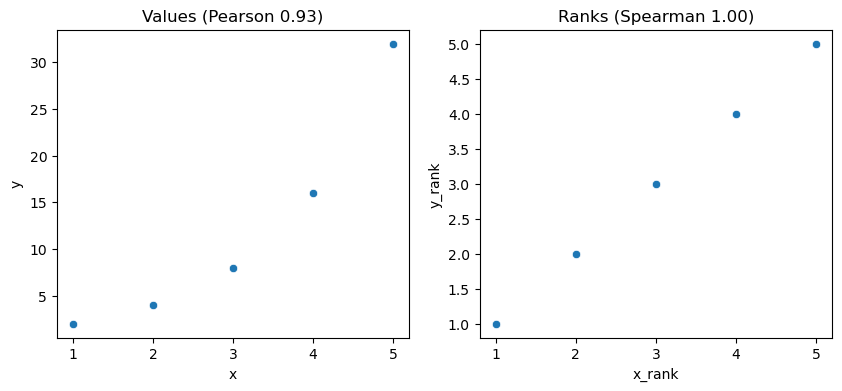

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.scatterplot(data=df, x='x', y='y', ax=axes[0])
axes[0].set_title('Values (Pearson 0.93)')

sns.scatterplot(data=df, x='x_rank', y='y_rank', ax=axes[1])
axes[1].set_title('Ranks (Spearman 1.00)')

plt.show()

- x가 커지면 y도 항상 커지지만, y가 곡선으로 늘어나므로 피어슨 상관계수는 0.93
- 값을 순위로 바꾸면 곡선이 **직선으로 바뀜**. 이 순위를 가지고 피어슨 상관계수를 구하면 1.0 이며, 이는 스피어만 상관계수와 같음
- `corr( )` 는 DataFrame 과 Series 에 모두 있으며, 여기서는 두 변수(Series)의 상관계수 하나를 구하는 방식을 사용함. 뒤에서 자세히 비교함

#### 예제 2. 도중에 방향이 바뀌는 관계

In [4]:
u = pd.DataFrame({'x': np.arange(-3, 4)})
u['y'] = 9 - u['x'] ** 2         # 올라갔다 내려감 (∩ 자 모양)

print(u.T)
print()
print("피어슨  :", round(u['x'].corr(u['y']), 3))
print("스피어만:", round(u['x'].corr(u['y'], method='spearman'), 3))

   0  1  2  3  4  5  6
x -3 -2 -1  0  1  2  3
y  0  5  8  9  8  5  0

피어슨  : 0.0
스피어만: 0.0


- y값은 x값에 의해서 전적으로 결정되는데도 두 상관계수 모두 0
- 스피어만은 "한 방향으로" 변하는 관계까지만 잡아냄
  - 증가하다가 감소하거나(∩ 자 모양), 감소하다가 증가하는(U 자 모양) 관계는 **두 상관계수 모두 잡아내지 못함**
- 그래서 상관계수를 구하기 전에 반드시 산점도로 모양을 확인해야 함

#### 예제 3. 순서형 데이터
- 식당 8곳의 가격대와 별점
  - 가격대 ₩, ₩₩, ₩₩₩, ₩₩₩₩ 를 1, 2, 3, 4 로 적음
  - 별점은 1 ~ 5

In [5]:
r = pd.DataFrame({'price_level': [1, 1, 2, 2, 3, 3, 4, 4],
                  'rating':      [2, 3, 3, 4, 4, 5, 4, 5]})

print("1, 2, 3, 4 로 적은 경우")
print("  피어슨  :", round(r['price_level'].corr(r['rating']), 3))
print("  스피어만:", round(r['price_level'].corr(r['rating'], method='spearman'), 3))

# 순서는 그대로 두고 가장 비싼 단계만 10 으로 적어 봄
# map( ) : 딕셔너리에 적힌 대로 값을 바꿈
r2 = r.assign(price_level = r['price_level'].map({1: 1, 2: 2, 3: 3, 4: 10}))

print("1, 2, 3, 10 으로 적은 경우")
print("  피어슨  :", round(r2['price_level'].corr(r2['rating']), 3))
print("  스피어만:", round(r2['price_level'].corr(r2['rating'], method='spearman'), 3))

1, 2, 3, 4 로 적은 경우
  피어슨  : 0.808
  스피어만: 0.81
1, 2, 3, 10 으로 적은 경우
  피어슨  : 0.584
  스피어만: 0.81


- 데이터의 **순서는 하나도 바뀌지 않았는데** 피어슨 상관계수는 0.81 에서 0.58 로 떨어짐
- 스피어만 상관계수는 순위만 사용하므로 그대로임
- 가격대, 만족도(1 ~ 5점) 같은 순서형 데이터의 숫자는 간격에 의미가 없음
  - 같은 순서라도 1, 2, 3, 4 로 정하느냐 1, 2, 3, 10 으로 정하느냐에 따라 피어슨 상관계수가 달라짐
  - 스피어만 상관계수는 순서만 사용하므로 숫자를 어떻게 정하든 같은 값이 나옴. 그래서 순서형 데이터에는 스피어만 상관계수가 알맞음

#### 상관계수 구하기: 자동차 데이터 (mtcars)

| 변수 | 의미 |
|---|---|
| `mpg` | 연비 (마일/갤런) |
| `cyl` | 실린더 수 |
| `disp` | 배기량 |
| `hp` | 마력 |
| `wt` | 무게 |

In [6]:
mtcars = pd.read_csv('mtcars.csv')
cars = mtcars[['mpg', 'cyl', 'disp', 'hp', 'wt']]
print(cars.head())

    mpg  cyl   disp   hp     wt
0  21.0    6  160.0  110  2.620
1  21.0    6  160.0  110  2.875
2  22.8    4  108.0   93  2.320
3  21.4    6  258.0  110  3.215
4  18.7    8  360.0  175  3.440


- `DataFrame.corr( )` : 모든 변수 쌍의 상관계수를 구한 상관 행렬을 돌려줌
  - 기본은 피어슨 상관계수. 스피어만 상관계수를 구할 때는 `method='spearman'` 지정
  - 문자열 열이 섞여 있으면 오류가 남. 숫자 열만 고르거나 `numeric_only=True` 지정

In [7]:
car_cor = cars.corr().round(2)
print(car_cor)

       mpg   cyl  disp    hp    wt
mpg   1.00 -0.85 -0.85 -0.78 -0.87
cyl  -0.85  1.00  0.90  0.83  0.78
disp -0.85  0.90  1.00  0.79  0.89
hp   -0.78  0.83  0.79  1.00  0.66
wt   -0.87  0.78  0.89  0.66  1.00


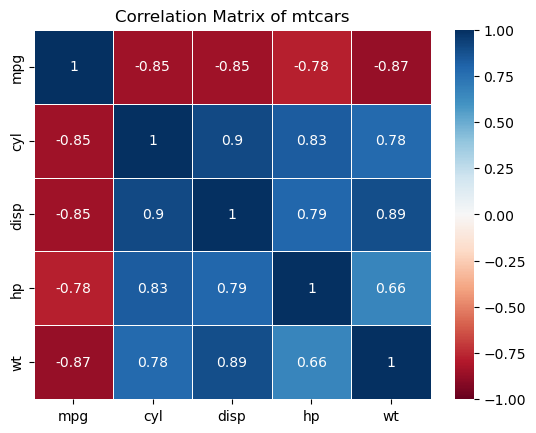

In [8]:
sns.heatmap(car_cor, annot=True, cmap='RdBu', vmin=-1, vmax=1, linewidths=0.5)

plt.title('Correlation Matrix of mtcars')
plt.show()

- `vmin=-1, vmax=1` : 색의 범위를 상관계수의 범위에 맞춤. 0 이 흰색이 되어 양수와 음수가 색으로 구분됨
- 연비(`mpg`)는 실린더 수, 배기량, 마력, 무게와 모두 강한 음의 상관관계
  - 크고 무겁고 힘이 센 차일수록 연비가 낮음

#### 두 가지 corr( ) 함수

| | `DataFrame.corr( )` | `Series.corr( 다른 Series )` |
|---|---|---|
| 쓰는 모양 | `cars.corr()` | `cars['mpg'].corr(cars['wt'])` |
| 대상 | 표 안의 모든 변수 쌍 | 두 변수 하나의 쌍 |
| 결과 | 상관 행렬 (DataFrame) | 상관계수 하나 (숫자) |
| 알맞은 경우 | 여러 변수를 한꺼번에 볼 때, heatmap 을 그릴 때 | 두 변수의 상관계수만 필요할 때 |

- 상관 행렬에서 두 변수가 만나는 칸의 값은, 그 두 변수를 Series 방식으로 구한 상관계수와 같음
  - 예: `cars.corr()` 의 `mpg` 행과 `wt` 열이 만나는 칸 = `cars['mpg'].corr(cars['wt'])`
  - 즉 상관 행렬은 모든 변수 쌍에 대해 Series 방식의 계산을 한꺼번에 해 놓은 표임

In [9]:
print("상관 행렬에서 꺼낸 값:", car_cor.loc['mpg', 'wt'])
print("Series 끼리 구한 값 :", round(cars['mpg'].corr(cars['wt']), 2))

상관 행렬에서 꺼낸 값: -0.87
Series 끼리 구한 값 : -0.87


---

### 상관 분석의 유의점 1. 상관계수가 같아도 관계는 다를 수 있음

- **Anscombe 데이터**: 통계학자 Anscombe가 1973년에 만든 데이터
  - 네 개의 데이터(I, II, III, IV)로 이루어져 있으며, 각각 x 와 y 두 변수가 있음

In [10]:
anscombe = sns.load_dataset('anscombe')
print(anscombe.head())

  dataset     x     y
0       I  10.0  8.04
1       I   8.0  6.95
2       I  13.0  7.58
3       I   9.0  8.81
4       I  11.0  8.33


### 아래 셀을 실행하기 전에 생각해 볼 것

- 아래 셀은 네 데이터 각각의 상관계수를 구하고, 그 다음 셀에서 산점도를 그림
- 상관계수가 비슷하다면 산점도의 모양도 비슷할까?

> 나의 예측:

In [ ]:
for name in ['I', 'II', 'III', 'IV']:
    part = anscombe.query('dataset == @name')
    print(name, round(part['x'].corr(part['y']), 3))

In [ ]:
sns.lmplot(data=anscombe, x='x', y='y', col='dataset', col_wrap=2)

plt.show()

<details>
<summary><b>결과 해설 보기</b> (클릭)</summary>
    
- 네 데이터의 상관계수는 모두 약 0.82 로 같지만 모양은 전혀 다름
  - I : 직선 관계에 가까움
  - II : 곡선 관계. 직선 관계만 재는 피어슨 상관계수로는 모양을 알 수 없음
  - III : 거의 완벽한 직선인데 이상치 하나가 상관계수를 낮춤
  - IV : 떨어져 있는 점 하나 때문에 높은 상관계수가 나옴
- 상관계수는 관계를 숫자 하나로 요약한 것일 뿐이므로 **반드시 산점도를 함께 확인**해야 함
- 이상치 하나가 상관계수를 얼마나 바꾸는지는 실습에서 직접 확인함
</details>

### 상관 분석의 유의점 2. 상관관계는 인과관계가 아님

- 두 변수 사이에 상관관계가 있어도 한 변수가 다른 변수의 원인이라는 뜻은 아님
- 예: 아이스크림 판매량과 물놀이 사고 건수는 양의 상관관계가 있음
  - 아이스크림이 사고를 일으키는 것이 아니라 **기온**이 두 변수에 함께 영향을 준 것
- 이처럼 두 변수 모두에 영향을 주는 제3의 변수를 **교란 변수(confounding variable)** 라고 함
  - 기온 → 아이스크림 판매량, 기온 → 물놀이 사고 건수
  - 교란 변수 때문에 두 변수 사이에 **실제로는 직접적인 관계가 없는데도 상관관계가 있는 것처럼** 보일 수 있음
  - 반대로 실제 관계를 **가리거나 뒤집어** 보이게 할 수도 있음 (아래 펭귄 예)

#### 예 1. 미국 경제 지표 (economics)
- `pce` : 개인 소비 지출, `unemploy` : 실업자 수, `pop` : 인구수 (1967 ~ 2015년, 월별)

In [13]:
economics = pd.read_csv('economics.csv')
print(economics[['pce', 'unemploy', 'pop']].corr().round(3))

            pce  unemploy    pop
pce       1.000     0.615  0.987
unemploy  0.615     1.000  0.634
pop       0.987     0.634  1.000


- 소비 지출과 실업자 수는 양의 상관관계(0.615)지만 "소비가 늘면 실업자가 는다"는 뜻이 아님
- 둘 다 인구수와 상관관계가 있음. 인구가 늘면서 **시간이 지남에 따라 함께 증가**한 결과일 가능성이 큼

#### 예 2. 펭귄의 부리 길이와 깊이
- 10주차에 본 심슨의 역설을 상관계수로 다시 확인함

In [14]:
penguins = sns.load_dataset('penguins')

print("전체:", round(penguins['bill_length_mm'].corr(penguins['bill_depth_mm']), 3))
for sp in ['Adelie', 'Chinstrap', 'Gentoo']:
    part = penguins.query('species == @sp')
    print(sp, round(part['bill_length_mm'].corr(part['bill_depth_mm']), 3))

전체: -0.235
Adelie 0.391
Chinstrap 0.654
Gentoo 0.643


- 전체는 음의 상관관계(-0.24)인데, 종별로 나누면 모두 양의 상관관계(0.39 ~ 0.65)
- 종이라는 교란 변수가 전체의 관계를 뒤집은 것
- 상관 분석 결과를 해석할 때는 **성격이 다른 그룹이 섞여 있지 않은지** 먼저 생각해야 함

---

## Part 2. 통계적 가설 검정 (Statistical hypothesis test)

#### 기술 통계와 추론 통계
- **기술 통계**: 데이터를 평균, 중앙값, 그래프 등으로 요약해 설명하는 방법
  - 지금까지 배운 `groupby( )`, `describe( )`, 그래프가 여기에 해당
- **추론 통계**: 일부(표본)만 관측하여 전체(모집단)의 특성을 추측하는 방법
  - 표본은 모집단의 일부이므로, 어떤 개체가 표본에 뽑혔는지에 따라 평균 같은 값이 달라짐
  - 따라서 표본에서 집단 간 차이가 보이더라도, 그 차이를 **그대로 모집단의 차이로 해석하면 잘못될 수 있음**
    - 예: penguins 데이터의 펭귄 333마리는 남극에 사는 펭귄 전체의 일부임. 다른 펭귄들을 측정했다면 종별 평균 차이가 달라졌을 수 있음
  - 표본의 차이가 **어떤 개체가 뽑혔느냐에 따른 우연**으로 생길 수 있는 정도인지, 모집단에도 차이가 있다고 볼 만한 정도인지 판단하는 절차가 **통계적 가설 검정**

In [15]:
peng = sns.load_dataset('penguins').dropna()

print(peng.groupby('species').agg(n=('body_mass_g', 'count'),
                                  mean_mass=('body_mass_g', 'mean')).round(1))

             n  mean_mass
species                  
Adelie     146     3706.2
Chinstrap   68     3733.1
Gentoo     119     5092.4


- Adelie와 Chinstrap의 평균 몸무게 차이는 약 27g, Adelie와 Gentoo의 차이는 약 1386g
- 두 차이 중 어느 것이 표본에 어떤 펭귄이 뽑혔느냐에 따라 우연히 생길 수 있는 차이이고, 어느 것이 모집단에도 있다고 볼 만한 차이일까?

- 차이의 **크기만으로는** 판단하기 어려움. 함께 봐야 할 것이 있음
  - **같은 종 안에서 개체 간 몸무게가 흩어진 정도**: 같은 종이라도 펭귄마다 몸무게가 많이 다르면, 측정 대상 펭귄 몇몇이 바뀌는 것만으로도 평균 차이가 쉽게 생길 수 있음
    - 세 종 모두 표준편차가 약 400 ~ 500g임. 27g은 같은 종 안의 차이에 비하면 아주 작은 차이
    - 시각화 내용에서 나왔던 상자 그림에서도 Adelie와 Chinstrap의 몸무게 데이터의 상자는 거의 겹치지만, Gentoo의 상자는 위로 떨어져 있음
  - **표본의 크기**: 각 종별로 몇 마리만 측정했다면 평균은 어느 개체가 뽑혔는지에 따라 크게 변할 수 있음. 표본이 클수록, 즉 많은 개체를 측정할수록 덜 변함
- 따라서 각 집단 안에서 값이 흩어진 정도와 표본의 크기를 함께 고려하여, 관찰한 차이가 우연만으로도 생길 수 있는 차이인지 판단하는 기준이 필요함
  - 이것이 아래에서 다룰 **통계적 가설 검정**

#### 가설
- 가설은 표본이 아니라 **모집단**에 대한 것임
  - 표본의 평균은 이미 Adelie (3706g), Chinstrap (3733g) 두 종이 다름. 궁금한 것은 해당 펭귄 종 전체에서도 다른가임
- **귀무가설** (null hypothesis, $H_0$): 비교하는 두 집단 **전체**의 평균에는 차이가 없다
  - 예: Adelie 펭귄 전체의 평균 몸무게와 Chinstrap 펭귄 전체의 평균 몸무게는 같다 ($\mu_A = \mu_C$)
- **대립가설** (alternative hypothesis, $H_1$): 비교하는 두 집단 **전체**의 평균에는 차이가 있다
  - 예: Adelie 펭귄 전체의 평균 몸무게와 Chinstrap 펭귄 전체의 평균 몸무게는 다르다 ($\mu_A \neq \mu_C$)
- 가설 검정은 **"귀무가설이 맞다면 지금 같은 차이가 얼마나 쉽게 나올 수 있는가"** 를 따져 보는 것

### 순열 검정으로 가설 검정의 원리 이해하기

#### 두 반의 시험 점수 예로 먼저 생각해 보기
- 두 반의 시험 평균이 5점 차이 난다고 해 보자. 이것을 **관찰한 차이**라고 하자.
- 이 차이는 반마다 무언가가 달라서(예: 수업 방식) 생긴 차이일까, 아니면 어떤 학생이 어느 반에 배정되었느냐에 따른 우연한 차이일까?
- 확인하는 방법
  - 점수는 그대로 둔 채 학생들을 **무작위로 다시 두 반으로 나누고**, 두 반의 평균 차이를 계산함. 이것을 **섞어서 나온 차이**라고 하자.
  - 이를 여러 번 반복함
  - 학생들을 무작위로 다시 나누었으므로 섞어서 나온 차이에는 수업 방식 같은 반의 차이가 들어 있지 않음. 즉 **배정에 따른 우연한 차이만으로 어느 정도 크기의 차이가 나오는지**를 보여 줌
- 섞어서 나온 차이들을 관찰한 차이(5점)와 비교함
  - 섞어서 나온 차이들 중에 크기가 5점 이상인 경우가 **흔하다면** → 관찰한 차이는 배정에 따른 우연한 차이로도 충분히 설명됨
  - 섞어서 나온 차이들 중에 크기가 5점 이상인 경우가 **거의 없다면** → 관찰한 차이는 우연한 차이로 보기 어려움. 반마다 무언가가 달라서 생긴 차이일 가능성이 높음

#### 펭귄에 적용하기
- 귀무가설이 맞다면, 즉 두 종의 몸무게에 차이가 없다면
  - 이름표를 떼고 몸무게만 보았을 때, 어느 펭귄이 어느 종인지 **구분할 수 없음**
  - 다시 말해 "Adelie"라는 이름표는 그 펭귄의 몸무게에 대해 **아무 정보도 주지 않음**
- 그렇다면 Adelie와 Chinstrap 펭귄 몸무게 214개에 이름표를 무작위로 다시 붙여도, 관찰한 데이터와 **같은 성격의 데이터**가 만들어질 것임
- Adelie 146마리, Chinstrap 68마리로 나뉜 지금의 구성은 **여러 가능한 나눔 중 하나**일 뿐임
- 그래서 다음을 반복함
  1. 두 종의 몸무게 214개를 한데 모음
  2. 무작위로 섞은 뒤 146개와 68개로 다시 나눔 (이름표를 무작위로 다시 붙이는 것과 같음)
  3. 두 집단의 평균 차이를 계산함 → **섞어서 나온 차이**
  4. 1 ~ 3 을 여러 번 반복함
- **관찰한 차이** 27g이 섞어서 나온 차이들 사이에서 얼마나 흔한 크기인지를 보고 판단함

- 이 방법을 **순열 검정(permutation test)** 이라고 함
  - 순열(permutation)은 순서를 바꾸어 늘어놓는다는 뜻. 값의 순서를 섞어서 다시 나누기 때문에 붙은 이름

In [16]:
rng = np.random.default_rng(0) # NumPy의 난수 생성기인 Generator를 반환

mass = np.array([10, 20, 30, 40, 50])
n_a = 3

# A그룹: 처음 3개, B그룹 나중 2개라고 가정하고 그룹 간 평균 차이를 보자
observed = mass[n_a:].mean() - mass[:n_a].mean()    # B 평균 - A 평균
print("관찰한 평균 차이:", observed)
print()

for i in range(3):
    shuffled = rng.permutation(mass)                  # 순서만 무작위로 섞음
    diff = shuffled[n_a:].mean() - shuffled[:n_a].mean()
    print(i + 1, "회차:", shuffled, "-> A", shuffled[:n_a], " B", shuffled[n_a:], " 평균 차이", round(diff, 2))

관찰한 평균 차이: 25.0

1 회차: [30 50 40 10 20] -> A [30 50 40]  B [10 20]  평균 차이 -25.0
2 회차: [50 20 30 10 40] -> A [50 20 30]  B [10 40]  평균 차이 -8.33
3 회차: [10 30 40 50 20] -> A [10 30 40]  B [50 20]  평균 차이 8.33


- `rng.permutation( )` : 값은 그대로 두고 순서만 무작위로 섞은 새 배열을 반환함
- 섞을 때마다 두 집단의 구성이 바뀌고 평균 차이도 달라짐
- 이제 펭귄 데이터로 1만 번 반복해 봄

### 아래 셀을 실행하기 전에 생각해 볼 것

- Adelie와 Chinstrap의 관찰한 차이는 약 27g임
- 이름표를 무작위로 1만 번 섞었을 때, 27g 이상의 차이가 나오는 경우는 **몇 % 정도**일까?

> 나의 예측:

In [ ]:
adelie    = peng.query('species == "Adelie"')['body_mass_g']
chinstrap = peng.query('species == "Chinstrap"')['body_mass_g']

observed = chinstrap.mean() - adelie.mean()
mass = pd.concat([adelie, chinstrap]).to_numpy()
n_a = len(adelie)

rng = np.random.default_rng(42)
diffs = []
for _ in range(10000):
    shuffled = rng.permutation(mass)
    diffs.append(shuffled[n_a:].mean() - shuffled[:n_a].mean())
diffs = np.array(diffs)

p_value = (np.abs(diffs) >= abs(observed)).mean()     # True 의 평균 = 비율

print("관찰한 차이:", round(observed, 1))
print("섞어서 나온 차이가 관찰한 차이 이상인 비율:", round(p_value, 3))

In [ ]:
sns.histplot(diffs, bins=50)
plt.axvline(observed, color='red')        # axvline( ) : 세로선을 그림
plt.axvline(-observed, color='red')

plt.title('Differences when Labels are Shuffled')
plt.xlabel('Difference in mean body mass (g)')
plt.show()

<details>
<summary><b>결과 해설 보기</b> (클릭)</summary>
    
- 히스토그램은 섞어서 나온 차이 1만 개의 분포
- 빨간 선 바깥쪽에 있는 비율이 약 0.68
  - 이름표를 아무렇게나 섞어도 열 번에 일곱 번꼴로 27g 이상의 차이가 남
  - 따라서 27g 차이는 **우연에 의한 차이로 충분히 설명되는 수준**
  - 빨간 선이 두 개인 이유: 오른쪽은 +27g, 왼쪽은 -27g. 어느 종이 더 무거운지가 아니라 **차이의 크기**를 보기 때문에 양쪽을 모두 셈
- 이 비율이 바로 **유의확률(p-value)**
</details>

#### 유의확률 (p-value)
- 귀무가설이 맞다고 가정했을 때, 관찰한 것만큼 또는 그보다 더 큰 차이가 우연히 나올 확률
- **유의수준**: 귀무가설을 기각할지 판단하는 기준값. 보통 0.05 (5%)

| 유의확률 | 판단 | 해석 |
|---|---|---|
| 유의수준보다 작음 | 귀무가설을 **기각** | 관찰한 차이가 통계적으로 유의함. 우연이라고 보기 어려움 |
| 유의수준보다 큼 | 귀무가설을 **기각할 수 없음** | 관찰한 차이가 통계적으로 유의하지 않음. 우연과 구분할 수 없음 |

- 유의확률이 유의수준보다 크다고 해서 "차이가 없다"는 것이 증명된 것은 아님
  - 재판에 비유하면 "증거 불충분으로 무죄"와 같음
    - 증거가 부족해 유죄라고 판단하지 못한 것이지, 결백하다는 것이 증명된 것은 아님
  - 가설 검정도 마찬가지로, 차이가 있다고 말할 **증거가 부족한 것**일 뿐임
- 펭귄의 예로 보면
  - 관찰한 차이 27g은 **이름표를 무작위로 섞었을 때에도 흔히 나오는 크기**였음
  - 그래서 "종에 따른 차이"인지 "어떤 펭귄이 어느 쪽에 들어갔느냐에 따른 우연"에 의한 차이인지 **구분할 수 없음**
  - 두 종의 몸무게가 실제로 20g 정도 다를 가능성도 있지만, 이 정도 차이는 지금의 데이터로는 우연과 구분되지 않음
- 따라서 결론은 "차이가 없다"가 아니라 **"차이가 있다고 할 수 없다"**, 가설의 표현으로는 "귀무가설을 채택한다"가 아니라 **"귀무가설을 기각할 수 없다"** 가 정확함

### t 검정

- 순열 검정은 이해하기 쉽지만 반복 계산이 필요함
- **t 검정**은 데이터가 정규분포를 따른다고 가정하고, 같은 질문에 대한 유의확률을 공식으로 한 번에 계산함
- 두 집단의 데이터 종류에 따라 검정 방법이 다름

| | 정규분포를 가정할 수 있음 (모수 검정, parametric test) | 정규분포를 가정할 수 없음 (비모수 검정, nonparametric test) |
|---|---|---|
| **독립 표본** (independent samples) : 서로 다른 개체 | 독립비교 t 검정 (independent two-sample t-test) : `ttest_ind( )` | 만-위트니 U 검정 (Mann-Whitney U test) : `mannwhitneyu( )` |
| **대응 표본** (paired samples) : 같은 개체를 두 번 측정 | 대응비교 t 검정 (paired t-test) : `ttest_rel( )` | 윌콕슨 부호순위 검정 (Wilcoxon signed-rank test) : `wilcoxon( )` |

- 표 안의 함수는 모두 scipy 패키지의 `stats` 모듈에 있음

- 독립 표본의 예: Adelie 펭귄의 몸무게와 Chinstrap 펭귄의 몸무게 (서로 다른 펭귄을 측정함)
- 대응 표본의 예: 같은 환자의 투약 전 혈압과 투약 후 혈압 (같은 사람을 두 번 측정함)

- scipy 패키지의 `ttest_ind( )` 함수 사용
  - `equal_var` : 두 집단의 분산이 같다고 가정하면 `True`, 다르면 `False`

In [19]:
from scipy import stats

peng = sns.load_dataset('penguins').dropna()

adelie = peng.query('species == "Adelie"')['body_mass_g']
chinstrap = peng.query('species == "Chinstrap"')['body_mass_g']
gentoo = peng.query('species == "Gentoo"')['body_mass_g']

print("Adelie vs Chinstrap:", stats.ttest_ind(adelie, chinstrap, equal_var=True).pvalue)
print()
print("Adelie vs Gentoo   :", stats.ttest_ind(adelie, gentoo, equal_var=True).pvalue)

Adelie vs Chinstrap: 0.6748289682757558

Adelie vs Gentoo   : 1.8806652580952688e-66


- Adelie vs Chinstrap 의 유의확률은 약 0.675 로, 순열 검정의 결과(약 0.68)와 거의 같음
  - 유의수준 0.05 보다 크므로 귀무가설을 **기각할 수 없음**
  - 두 종의 몸무게 차이는 통계적으로 유의하지 않음
- Adelie vs Gentoo 의 유의확률은 0 에 매우 가까움
  - 귀무가설을 **기각**함. 두 종의 몸무게 차이는 통계적으로 유의함

### 결과를 해석할 때 주의할 점

#### 1. 통계적으로 유의한 것과 의미 있는 것은 다름

- "통계적으로 유의하다"는 **우연으로 보기 어렵다**는 뜻이지, 차이가 **크다**거나 **중요하다**는 뜻이 아님
- 표본이 클수록 평균이 덜 변하므로, 작은 차이도 우연히 생길 수 있는 차이와 구분되어 유의하게 나올 수 있음
- 아래는 평균 차이가 1로 같은 두 집단을 표본 크기만 바꾸어 비교한 예

In [20]:
rng = np.random.default_rng(0)

for n in [20, 200, 2000, 20000]:
    a = rng.normal(100, 10, n)               # 평균 100, 표준편차 10 인 값 n 개
    b = rng.normal(100, 10, n)
    b = b - b.mean() + a.mean() + 1          # 두 집단의 평균 차이를 정확히 1 로 맞춤
    p = stats.ttest_ind(a, b).pvalue
    print(f"표본 크기 {n:>6} : 평균 차이 {b.mean() - a.mean():5.2f}, 유의확률 {p:.4f}")

표본 크기     20 : 평균 차이  1.00, 유의확률 0.6940
표본 크기    200 : 평균 차이  1.00, 유의확률 0.3316
표본 크기   2000 : 평균 차이  1.00, 유의확률 0.0015
표본 크기  20000 : 평균 차이  1.00, 유의확률 0.0000


- 차이는 모두 1 인데, 표본이 커지자 유의확률이 0에 가까워짐
- 예: 펭귄을 아주 많이 측정하면 몸무게 20g 차이도 유의하게 나올 수 있음. 그러나 약 3700g 중 20g이 중요한 차이인지는 별개의 문제임
- 따라서 **유의확률**(우연히 나타날 수 있는 차이인가?)과 **차이의 크기**(차이가 의미 있는 크기인가?)를 함께 확인해야 함

#### 2. 여러 번 비교할수록 차이가 없는데도 유의하게 나올 가능성이 커짐

- 유의수준 0.05는 차이가 없을 때도 20번에 1번꼴로 유의하게 나올 수 있다는 뜻
- 비교를 여러 번 하면, 그중 적어도 하나가 유의하게 나올 가능성이 커짐
  - 3번 비교 (세 종을 두 종씩): 약 14%
  - 45번 비교 (열 개 집단을 두 집단씩): 약 90%
- 따라서 여러 번 비교한 뒤 **유의하게 나온 결과만 골라서 결론을 내리면 안 됨**
- 여러 집단을 비교할 때는 이런 점을 고려한 방법(분산분석 등)을 사용함. 이 수업에서는 다루지 않음

#### 참고. 정규분포를 가정하기 어려운 경우
- 앞의 표에 있는 비모수 검정(만-위트니 U 검정 등)을 사용함
- 값 대신 순위를 사용하므로 이상치의 영향을 덜 받음 (스피어만 상관계수와 같은 아이디어)